# Phase 1 — Full-Split Pseudo-Label Generation & Threshold Datasets

**Low-Light Object Detection via Decoupled VLM Pseudo-Labelling (RF-DETR pipeline)**

Consumes the Phase 0 decision (**YOLO-World v8 · enhanced · threshold 0.60**) and scales the annotation
run from the 600-image probe to the **full ExDark training split**. It confirms the raw-vs-enhanced
finding at scale, sweeps thresholds 0.55–0.75, and emits RF-DETR-ready COCO datasets for Conditions
A (raw+human), B (enhanced+human), and C (enhanced+VLM pseudo-labels).


## 1. Install dependencies

Same pins as Phase 0 so the teacher behaves identically. `ultralytics` provides YOLO-World v8;
`pyarrow` caches the large prediction table as Parquet.


In [1]:
!pip install -q \
    "transformers>=4.55,<5.0" \
    "numpy>=1.26,<2.1" \
    "pandas>=2.0,<2.3" \
    "pyarrow" "pillow" "matplotlib" "seaborn" "scipy" "tqdm" "gdown" "ultralytics"
# torch / torchvision ship with the Colab runtime already built against its CUDA — do NOT reinstall.

import torch, numpy, pandas, ultralytics
print("torch:", torch.__version__)
print("numpy:", numpy.__version__, "| pandas:", pandas.__version__)
print("ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
torch

## 2. Configuration

Classes and `PROMPT_MAP` are carried over verbatim from Phase 0 so pseudo-labels use identical prompts.
Threshold sweep is 0.55–0.75 (0.80 dropped. Phase 0 showed it starves rare classes). All Phase 1
artefacts are written to **new `_yoloworld_v8` subfolders** so the earlier MM-GroundingDINO run is
preserved; only the teacher-independent enhanced image pool is shared and reused.


In [12]:
import os
from dataclasses import dataclass

# ── ExDark canonical classes (12) — identical to Phase 0 ──
EXDARK_CLASSES = ["Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
                  "Chair", "Cup", "Dog", "Motorbike", "People", "Table"]

PROMPT_MAP = {
    "Bicycle": "bicycle", "Boat": "boat", "Bottle": "bottle", "Bus": "bus",
    "Car": "car", "Cat": "cat", "Chair": "chair", "Cup": "cup", "Dog": "dog",
    "Motorbike": "motorcycle", "People": "person", "Table": "table",
}
PROMPT_TO_CLASS = {v: k for k, v in PROMPT_MAP.items()}
PROMPTS = [PROMPT_MAP[c] for c in EXDARK_CLASSES]

# COCO category ids (1-indexed, standard COCO)
CLASS_TO_CATID = {c: i + 1 for i, c in enumerate(EXDARK_CLASSES)}
COCO_CATEGORIES = [{"id": i + 1, "name": c, "supercategory": "object"}
                   for i, c in enumerate(EXDARK_CLASSES)]

RUN_TAG = "yoloworld_v8"   # suffix for every Phase 1 output folder in this run

@dataclass
class Config:
    # ── Dataset (same layout as Phase 0) ──
    drive_root: str = "/content/drive/MyDrive/ExDark_dataset"
    images_dir: str = "/content/drive/MyDrive/ExDark_dataset/ExDark"        # <class>/<image>
    annot_dir:  str = "/content/drive/MyDrive/ExDark_dataset/ExDark_Annno"  # <class>/<image>.txt

    # ── Train / val / test split (ExDark defines none; seed-42 stratified) ──
    split_ratios: tuple = (0.80, 0.10, 0.10)
    random_seed: int = 42

    # ── Teacher: YOLO-World v8, selected in Phase 0 ──
    yoloworld_id: str = "yolov8x-worldv2.pt"
    teacher_name: str = "YOLO-World"

    # ── Threshold sweep for pseudo-label datasets ──
    thresholds: tuple = (0.55, 0.60, 0.65, 0.70, 0.75)
    iou_match: float = 0.50        # IoU >= this counts a prediction as matching a GT box
    infer_threshold: float = 0.05  # keep everything above this at inference; filter later

    # ── Zero-DCE (identical to Phase 0) ──
    zerodce_weights_url: str = ("https://raw.githubusercontent.com/Li-Chongyi/"
                                "Zero-DCE/master/Zero-DCE_code/snapshots/Epoch99.pth")
    zerodce_max_side: int = 1200
    enh_ext: str = ".png"          # lossless, so JPEG noise doesn't confound the enhancement question

    # ── Persistent output locations (Drive, so runs are resumable) ──
    # The enhanced pool is teacher-independent -> shared with the earlier run to avoid re-enhancing 7,363 images.
    enhanced_pool_dir: str = "/content/drive/MyDrive/ExDark_dataset/ExDark_enhanced"
    # These ARE teacher-specific -> new subfolders for the YOLO-World run.
    pred_cache_dir:    str = f"/content/drive/MyDrive/ExDark_dataset/phase1_predictions_{RUN_TAG}"
    outputs_dir:       str = f"/content/drive/MyDrive/ExDark_dataset/phase1_outputs_{RUN_TAG}"

    # ── Materialised RF-DETR datasets ──
    materialize_root: str = "/content/phase1_datasets"   # local build dir (ephemeral)
    image_mode: str = "copy"       # real files, needed for zipping/portability
    persist_to_drive: bool = True
    dataset_zip_dir: str = f"/content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_{RUN_TAG}"

    save_every: int = 200          # inference checkpoint interval

CFG = Config()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ENH_EXT = CFG.enh_ext
for d in (CFG.enhanced_pool_dir, CFG.pred_cache_dir, CFG.outputs_dir):
    os.makedirs(d, exist_ok=True)

print("Device:", DEVICE)
print("Teacher:", CFG.teacher_name, f"({CFG.yoloworld_id})")
print("Threshold sweep:", CFG.thresholds)
print("Outputs   ->", CFG.outputs_dir)
print("Pred cache->", CFG.pred_cache_dir)
print("Zips      ->", CFG.dataset_zip_dir)
print("Enh pool  ->", CFG.enhanced_pool_dir, "(shared / reused)")


Device: cuda
Teacher: YOLO-World (yolov8x-worldv2.pt)
Threshold sweep: (0.55, 0.6, 0.65, 0.7, 0.75)
Outputs   -> /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8
Pred cache-> /content/drive/MyDrive/ExDark_dataset/phase1_predictions_yoloworld_v8
Zips      -> /content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_yoloworld_v8
Enh pool  -> /content/drive/MyDrive/ExDark_dataset/ExDark_enhanced (shared / reused)


## 3. Mount Drive & load the Phase 0 decision

Clears any stale mount before mounting (Colab refuses a non-empty mountpoint), then loads
`phase0_decision.json`, preferring the new `phase0_outputs_yoloworld_v8/` folder. Falls back to the
Phase 0 result (YOLO-World · enhanced · 0.60) with a warning if no file is found.


In [4]:
import json, glob, os
from google.colab import drive

os.system("fusermount -u /content/drive 2>/dev/null")
os.system("rm -rf /content/drive")
drive.mount("/content/drive")

CFG.drive_root = "/content/drive/MyDrive/ExDark_dataset"
CFG.images_dir = os.path.join(CFG.drive_root, "ExDark")
CFG.annot_dir  = os.path.join(CFG.drive_root, "ExDark_Annno")

print("images_dir:", CFG.images_dir, "| exists:", os.path.isdir(CFG.images_dir))
print("annot_dir :", CFG.annot_dir,  "| exists:", os.path.isdir(CFG.annot_dir))
assert os.path.isdir(CFG.images_dir) and os.path.isdir(CFG.annot_dir), \
    "ExDark folders not visible — do Runtime -> Restart session, then run again."

def load_phase0_decision(cfg):
    # Prefer the YOLO-World Phase 0 run, then older locations.
    candidates = [
        os.path.join(cfg.drive_root, f"phase0_outputs_{RUN_TAG}", "phase0_decision.json"),
        os.path.join(cfg.outputs_dir, "phase0_decision.json"),
        os.path.join(cfg.drive_root, "phase0_outputs", "phase0_decision.json"),
        os.path.join(cfg.drive_root, "phase0_decision.json"),
    ]
    candidates += sorted(glob.glob(os.path.join(cfg.drive_root, "**", "phase0_decision.json"),
                                   recursive=True))
    for p in candidates:
        if os.path.isfile(p):
            with open(p) as f:
                d = json.load(f)
            print(f"[phase0] loaded decision from: {p}")
            return d
    print("[phase0][WARN] phase0_decision.json not found — falling back to the Phase 0 result "
          "(YOLO-World · enhanced · 0.60).")
    return {"selected_teacher": "YOLO-World", "selected_condition": "enhanced",
            "selected_threshold": 0.60}

PHASE0 = load_phase0_decision(CFG)
SELECTED_TEACHER   = PHASE0.get("selected_teacher", "YOLO-World")
SELECTED_CONDITION = PHASE0.get("selected_condition", "enhanced")
SELECTED_THRESHOLD = float(PHASE0.get("selected_threshold", 0.60))
print("Phase 0 decision:", json.dumps(PHASE0, indent=2))

# Guard: this notebook implements the YOLO-World teacher. A different selection means the wrong
# Phase 0 file was picked up.
if "yolo" not in SELECTED_TEACHER.lower():
    print(f"\n[WARN] Phase 0 selected '{SELECTED_TEACHER}', but this notebook runs YOLO-World v8. "
          "Check that the intended phase0_decision.json was loaded before continuing.")


Mounted at /content/drive
images_dir: /content/drive/MyDrive/ExDark_dataset/ExDark | exists: True
annot_dir : /content/drive/MyDrive/ExDark_dataset/ExDark_Annno | exists: True
[phase0] loaded decision from: /content/drive/MyDrive/ExDark_dataset/phase0_outputs_yoloworld_v8/phase0_decision.json
Phase 0 decision: {
  "selected_teacher": "YOLO-World",
  "selected_condition": "enhanced",
  "selected_threshold": 0.6,
  "precision": 0.8486,
  "kept_boxes": 1255,
  "min_class_survival": 13,
  "min_per_class_requirement": 10,
  "sample_size": 600
}


## 4. Verify the ExDark dataset is present

Non-fatal integrity check over the 12 class folders — prints mismatched rows and continues as long as a
usable number of images is present.


In [5]:
EXPECTED_TOTAL_IMAGES = 7363
PER_CLASS_EXPECTED = {
    "Bicycle":652, "Boat":679, "Bottle":547, "Bus":527, "Car":638, "Cat":735,
    "Chair":648, "Cup":519, "Dog":801, "Motorbike":503, "People":609, "Table":505,
}

def find_class_dir(root, cls):
    for cand in [cls, cls.lower(), cls.replace(" ", "_")]:
        p = os.path.join(root, cand)
        if os.path.isdir(p):
            return p
    return None

def verify_complete(cfg):
    if not os.path.isdir(cfg.images_dir):
        print(f"[MISSING] images_dir: {cfg.images_dir}"); return False
    if not os.path.isdir(cfg.annot_dir):
        print(f"[MISSING] annot_dir: {cfg.annot_dir}"); return False
    print(f"{'Class':<10} {'images':>8} {'expected':>9} {'annots':>8}")
    print("-" * 40)
    total_img, problems = 0, []
    for c in EXDARK_CLASSES:
        idir, adir = find_class_dir(cfg.images_dir, c), find_class_dir(cfg.annot_dir, c)
        n_img = len([p for p in glob.glob(os.path.join(idir, "*"))
                     if p.lower().endswith((".png",".jpg",".jpeg",".bmp"))]) if idir else 0
        n_ann = len(glob.glob(os.path.join(adir, "*.txt"))) if adir else 0
        exp = PER_CLASS_EXPECTED[c]; total_img += n_img
        flag = "" if (n_img == exp and n_ann >= exp) else "  <-- MISMATCH"
        if flag: problems.append(c)
        print(f"{c:<10} {n_img:>8} {exp:>9} {n_ann:>8}{flag}")
    print("-" * 40)
    print(f"{'TOTAL':<10} {total_img:>8} {EXPECTED_TOTAL_IMAGES:>9}")
    ok = (total_img == EXPECTED_TOTAL_IMAGES and not problems)
    print("\n[OK] Full ExDark dataset present." if ok else
          "\n[PARTIAL] Counts differ from the official dataset (see MISMATCH rows above).")
    return ok

_ok = verify_complete(CFG)
if not _ok:
    have_imgs = sum(len([p for p in glob.glob(os.path.join(find_class_dir(CFG.images_dir, c) or "", "*"))
                         if p.lower().endswith((".png",".jpg",".jpeg",".bmp"))])
                    for c in EXDARK_CLASSES)
    if have_imgs >= 1000:
        print(f"\n[continue] Proceeding with {have_imgs} images found.")
    else:
        raise AssertionError(
            f"Only {have_imgs} images found — dataset looks incomplete. Verify ExDark extracted fully "
            f"under {CFG.images_dir} (12 class subfolders) before continuing.")


Class        images  expected   annots
----------------------------------------
Bicycle         652       652      652
Boat            679       679      679
Bottle          547       547      547
Bus             527       527      527
Car             638       638      638
Cat             735       735      735
Chair           648       648      648
Cup             519       519      519
Dog             801       801      801
Motorbike       503       503      503
People          609       609      609
Table           505       505      505
----------------------------------------
TOTAL          7363      7363

[OK] Full ExDark dataset present.


## 4.5 Stage the dataset to local disk

Drive's FUSE mount does a network round-trip per file. Copying the raw images and annotations to local
SSD once makes every later pass much faster. Only raw inputs move local — the enhanced pool, prediction
cache and outputs stay on Drive. **Re-run this cell after any reconnect** (it skips if already staged).


In [6]:
import shutil, time

LOCAL_STAGE = "/content/exdark_local"
os.makedirs(LOCAL_STAGE, exist_ok=True)

def _class_dir_count(root):
    if not os.path.isdir(root):
        return 0
    subs = {d.lower() for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))}
    return sum(c.lower() in subs for c in EXDARK_CLASSES)

def _count_files(root, exts):
    n = 0
    for c in EXDARK_CLASSES:
        cd = find_class_dir(root, c)
        if cd:
            n += sum(1 for p in glob.glob(os.path.join(cd, "*")) if p.lower().endswith(exts))
    return n

def stage_folder(src, dst, exts, label):
    """Copy src->dst once (skip if already complete), then verify file counts match the source."""
    src_n = _count_files(src, exts)
    if _class_dir_count(dst) >= 12 and _count_files(dst, exts) >= src_n and src_n > 0:
        print(f"[stage] {label}: already staged ({_count_files(dst, exts)} files) -> {dst}")
        return
    t = time.time()
    print(f"[stage] {label}: copying {src_n} files from Drive to local (one-time)...")
    shutil.copytree(src, dst, dirs_exist_ok=True)
    dst_n = _count_files(dst, exts)
    print(f"[stage]   done in {time.time()-t:.0f}s — {dst_n}/{src_n} files, "
          f"{_class_dir_count(dst)}/12 classes")
    if dst_n < src_n:
        raise IOError(f"{label}: staged {dst_n} files but source has {src_n} — copy incomplete, re-run.")

img_dst = os.path.join(LOCAL_STAGE, "ExDark")
ann_dst = os.path.join(LOCAL_STAGE, "ExDark_Annno")
stage_folder(CFG.images_dir, img_dst, (".png", ".jpg", ".jpeg", ".bmp"), "images")
stage_folder(CFG.annot_dir,  ann_dst, (".txt",),                         "annotations")

CFG.images_dir = img_dst
CFG.annot_dir  = ann_dst
print("\n[stage] CFG.images_dir ->", CFG.images_dir)
print("[stage] CFG.annot_dir  ->", CFG.annot_dir)


[stage] images: copying 7363 files from Drive to local (one-time)...
[stage]   done in 314s — 7363/7363 files, 12/12 classes
[stage] annotations: copying 7363 files from Drive to local (one-time)...
[stage]   done in 97s — 7363/7363 files, 12/12 classes

[stage] CFG.images_dir -> /content/exdark_local/ExDark
[stage] CFG.annot_dir  -> /content/exdark_local/ExDark_Annno


## 5. Parse annotations & build the train / val / test split

ExDark defines no official split, so Phase 1 builds a deterministic seed-42 stratified split by primary
class (80/10/10). Width/height are cached here so the COCO export never re-opens the files. The manifest
is cached to Drive; change `split_ratios` or `random_seed` to force a rebuild.


In [13]:
import random, hashlib
from PIL import Image
from tqdm.auto import tqdm

def parse_bbgt(txt_path):
    """Parse an ExDark bbGt annotation file -> list of (ExDark_class, [x1,y1,x2,y2])."""
    boxes = []
    if not txt_path or not os.path.isfile(txt_path):
        return boxes
    with open(txt_path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("%") or line.lower().startswith("class"):
                continue
            parts = line.split()
            if len(parts) < 5:
                continue
            canon = next((c for c in EXDARK_CLASSES if c.lower() == parts[0].lower()), None)
            if canon is None:
                continue
            try:
                l, t, w, h = map(float, parts[1:5])
            except ValueError:
                continue
            boxes.append((canon, [l, t, l + w, t + h]))
    return boxes

def annot_path_for(cfg, cls, image_filename):
    d = find_class_dir(cfg.annot_dir, cls)
    if d is None:
        return None
    cand = os.path.join(d, image_filename + ".txt")
    if os.path.isfile(cand):
        return cand
    stem = os.path.splitext(image_filename)[0]
    for alt in [stem + ".txt", stem + ".png.txt", stem + ".jpg.txt"]:
        p = os.path.join(d, alt)
        if os.path.isfile(p):
            return p
    return None

SPLIT_CACHE = os.path.join(CFG.outputs_dir, "split_manifest.json")

def _fingerprint(cfg):
    key = f"{cfg.split_ratios}|{cfg.random_seed}|{cfg.images_dir}"
    return hashlib.md5(key.encode()).hexdigest()

def _stratified_assign(samples, cfg):
    by_cls = {}
    for s in samples:
        by_cls.setdefault(s["primary_class"], []).append(s)
    rng = random.Random(cfg.random_seed)
    tr, va, te = cfg.split_ratios
    for cls, lst in by_cls.items():
        rng.shuffle(lst)
        n = len(lst); n_tr = int(n * tr); n_va = int(n * va)
        for i, s in enumerate(lst):
            s["split"] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")

def build_full_manifest(cfg, force=False):
    fp = _fingerprint(cfg)
    if not force and os.path.isfile(SPLIT_CACHE):
        try:
            man = json.load(open(SPLIT_CACHE))
            if man.get("fingerprint") == fp:
                print(f"[cached] split manifest: {SPLIT_CACHE}")
                for s in man["samples"]:
                    s["gt"] = [(g[0], g[1]) for g in s["gt"]]
                return man["samples"]
            print("[cache miss] split parameters changed — rebuilding.")
        except Exception as e:
            print(f"[cache miss] could not read manifest ({e}) — rebuilding.")

    samples = []
    for c in EXDARK_CLASSES:
        idir = find_class_dir(cfg.images_dir, c)
        if idir is None:
            continue
        imgs = sorted(p for p in glob.glob(os.path.join(idir, "*"))
                      if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")))
        for p in tqdm(imgs, desc=f"scan {c}", leave=False):
            fn = os.path.basename(p)
            try:
                with Image.open(p) as im:
                    w, h = im.size
            except Exception:
                continue
            gt = parse_bbgt(annot_path_for(cfg, c, fn))
            samples.append({"path": p, "key": p, "primary_class": c, "filename": fn,
                            "width": w, "height": h, "split": None, "gt": gt})

    _stratified_assign(samples, cfg)
    man = {"fingerprint": fp, "n": len(samples), "samples": samples}
    os.makedirs(os.path.dirname(SPLIT_CACHE), exist_ok=True)
    json.dump(man, open(SPLIT_CACHE, "w"))
    print(f"[saved] split manifest -> {SPLIT_CACHE}")
    return samples

SAMPLES = build_full_manifest(CFG)

from collections import Counter
print(f"\nTotal images: {len(SAMPLES)}")
print("Split sizes :", dict(Counter(s["split"] for s in SAMPLES)))
for split in ["train", "val", "test"]:
    sub = [s for s in SAMPLES if s["split"] == split]
    print(f"  {split:<5}: {len(sub):>5} images, {sum(len(s['gt']) for s in sub):>6} GT boxes")

TRAIN = [s for s in SAMPLES if s["split"] == "train"]
TRAIN_GT_TOTAL = sum(len(s["gt"]) for s in TRAIN)
print(f"\nTrain GT boxes (denominator for recall): {TRAIN_GT_TOTAL}")


[cache miss] split parameters changed — rebuilding.


scan Bicycle:   0%|          | 0/652 [00:00<?, ?it/s]

scan Boat:   0%|          | 0/679 [00:00<?, ?it/s]

scan Bottle:   0%|          | 0/547 [00:00<?, ?it/s]

scan Bus:   0%|          | 0/527 [00:00<?, ?it/s]

...

scan Dog:   0%|          | 0/801 [00:00<?, ?it/s]

scan Motorbike:   0%|          | 0/503 [00:00<?, ?it/s]

scan People:   0%|          | 0/609 [00:00<?, ?it/s]

scan Table:   0%|          | 0/505 [00:00<?, ?it/s]

[saved] split manifest -> /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/split_manifest.json

Total images: 7363
Split sizes : {'train': 5886, 'val': 729, 'test': 748}
  train:  5886 images,  19105 GT boxes
  val  :   729 images,   2387 GT boxes
  test :   748 images,   2218 GT boxes

Train GT boxes (denominator for recall): 19105


## 6. Zero-DCE enhancement: build the enhanced image pool

Identical architecture and weights to Phase 0, but every enhanced image is written to a persistent Drive
pool (lossless PNG) rather than cached in RAM. The pool feeds both VLM inference and the Condition B/C
training sets with pixel-identical inputs. The pass is resumable and **shared with the earlier Phase 1
run** — already-enhanced files are skipped, so this usually completes in seconds.


[cached] Zero-DCE weights: /content/drive/MyDrive/ExDark_dataset/weights/zerodce_Epoch99.pth


Enhancing pool:   0%|          | 0/7363 [00:00<?, ?it/s]

Enhanced pool ready — new: 0, cached: 7363, failed: 0


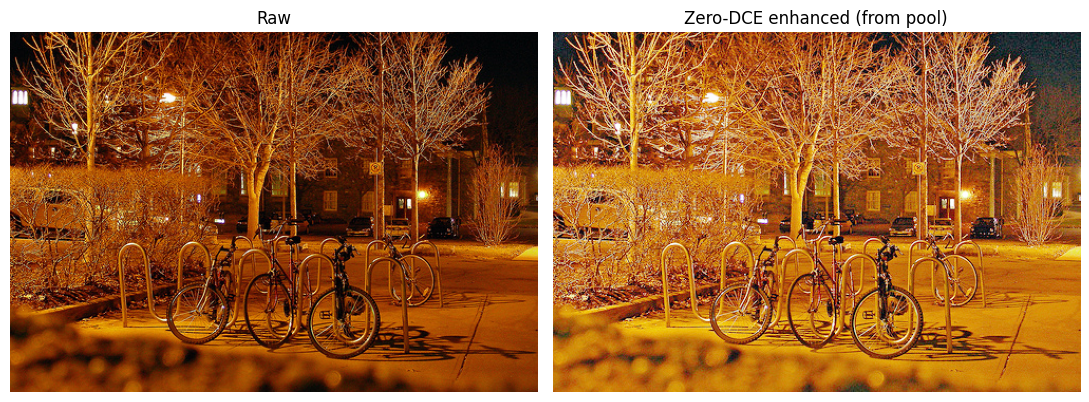

In [8]:
import torch.nn as nn
import numpy as np

class DCE_Net(nn.Module):
    """Official Zero-DCE enhance_net_nopool architecture."""
    def __init__(self, number_f=32):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.e_conv1 = nn.Conv2d(3, number_f, 3, 1, 1, bias=True)
        self.e_conv2 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv3 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv4 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv5 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv6 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv7 = nn.Conv2d(number_f * 2, 24, 3, 1, 1, bias=True)

    def forward(self, x):
        x1 = self.relu(self.e_conv1(x))
        x2 = self.relu(self.e_conv2(x1))
        x3 = self.relu(self.e_conv3(x2))
        x4 = self.relu(self.e_conv4(x3))
        x5 = self.relu(self.e_conv5(torch.cat([x3, x4], 1)))
        x6 = self.relu(self.e_conv6(torch.cat([x2, x5], 1)))
        x_r = torch.tanh(self.e_conv7(torch.cat([x1, x6], 1)))
        r = torch.split(x_r, 3, dim=1)
        for i in range(8):
            x = x + r[i] * (torch.pow(x, 2) - x)
        return x

def load_zerodce(cfg):
    import urllib.request
    wdir = os.path.join(cfg.drive_root, "weights")
    os.makedirs(wdir, exist_ok=True)
    wpath = os.path.join(wdir, "zerodce_Epoch99.pth")

    def _valid(path):
        if not os.path.isfile(path) or os.path.getsize(path) < 100_000:
            return False
        try:
            torch.load(path, map_location="cpu"); return True
        except Exception:
            return False

    if not _valid(wpath):
        print("Downloading Zero-DCE weights...")
        got = False
        try:
            req = urllib.request.Request(cfg.zerodce_weights_url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open(wpath, "wb") as f:
                f.write(r.read())
            got = _valid(wpath)
        except Exception as e:
            print("  direct download failed:", e)
        if not got:
            os.system(f'wget -q -O "{wpath}" "{cfg.zerodce_weights_url}"')
            got = _valid(wpath)
        if not got:
            raise RuntimeError("Could not obtain Zero-DCE Epoch99.pth; download it manually to " + wpath)
        print("  weights verified:", wpath)
    else:
        print("[cached] Zero-DCE weights:", wpath)

    state = torch.load(wpath, map_location="cpu")
    state = {(k[7:] if k.startswith("module.") else k): v for k, v in state.items()}
    net = DCE_Net(); net.load_state_dict(state); net.eval().to(DEVICE)
    return net

ZERODCE = load_zerodce(CFG)

@torch.no_grad()
def enhance_pil(pil_img, cfg=CFG):
    img = pil_img.convert("RGB")
    w, h = img.size
    scale = min(1.0, cfg.zerodce_max_side / max(w, h))
    if scale < 1.0:
        img = img.resize((int(w * scale), int(h * scale)), Image.BILINEAR)
    arr = np.asarray(img).astype(np.float32) / 255.0
    ten = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    out = ZERODCE(ten).clamp(0, 1)
    out = (out.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    enh = Image.fromarray(out)
    if scale < 1.0:
        enh = enh.resize((w, h), Image.BILINEAR)   # restore size -> GT coords stay valid
    return enh

def enhanced_path(cfg, s):
    stem = os.path.splitext(s["filename"])[0]
    return os.path.join(cfg.enhanced_pool_dir, s["primary_class"], stem + cfg.enh_ext)

def build_enhanced_pool(cfg, samples):
    made = skipped = failed = 0
    for s in tqdm(samples, desc="Enhancing pool"):
        dst = enhanced_path(cfg, s)
        if os.path.isfile(dst) and os.path.getsize(dst) > 0:
            skipped += 1; continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        try:
            enhance_pil(Image.open(s["path"])).save(dst)
            made += 1
        except Exception as e:
            failed += 1
            if failed <= 5:
                print(f"[warn] enhance failed on {s['filename']}: {e}")
    print(f"Enhanced pool ready — new: {made}, cached: {skipped}, failed: {failed}")

build_enhanced_pool(CFG, SAMPLES)

import matplotlib.pyplot as plt
_s = TRAIN[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(Image.open(_s["path"]).convert("RGB")); ax[0].set_title("Raw"); ax[0].axis("off")
ax[1].imshow(Image.open(enhanced_path(CFG, _s)).convert("RGB"))
ax[1].set_title("Zero-DCE enhanced (from pool)"); ax[1].axis("off")
plt.tight_layout(); plt.show()


## 7. Load the selected teacher (YOLO-World v8)

Only the Phase-0-selected teacher is loaded. `set_classes(PROMPTS)` fixes the open-vocabulary head to the
12 ExDark prompts, so returned class indices map straight back to `EXDARK_CLASSES` — the same wrapper the
probe validated.


In [9]:
from ultralytics import YOLOWorld

print("Loading teacher — YOLO-World v8 ...")
yoloworld_model = YOLOWorld(CFG.yoloworld_id)
yoloworld_model.set_classes(PROMPTS)   # index i -> EXDARK_CLASSES[i]
print("Teacher loaded.")

def run_yoloworld(pil_img):
    """-> list of (ExDark_class, [x1,y1,x2,y2], score), everything above infer_threshold."""
    r = yoloworld_model.predict(
        pil_img, conf=CFG.infer_threshold, verbose=False,
        device=0 if DEVICE == "cuda" else "cpu",
    )[0]
    dets = []
    if r.boxes is not None and len(r.boxes):
        for box, score, cls_idx in zip(r.boxes.xyxy.tolist(),
                                       r.boxes.conf.tolist(),
                                       r.boxes.cls.tolist()):
            idx = int(cls_idx)
            if 0 <= idx < len(EXDARK_CLASSES):
                dets.append((EXDARK_CLASSES[idx], [float(v) for v in box], float(score)))
    return dets

# smoke test
_d = run_yoloworld(Image.open(TRAIN[0]["path"]).convert("RGB"))
print(f"Smoke test: {len(_d)} detections"
      + (f"  e.g. {_d[0][0]} @ {_d[0][2]:.2f}" if _d else "  (none above infer_threshold)"))


Loading teacher — YOLO-World v8 ...
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 37 packages in 774ms
Prepared 2 packages in 2.50s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@c4b6ea0932a2c0f39a0fa528af5ec4982ff15cab)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|███████████████████████████████████████| 338M/338M [00:03<00:00, 92.5MiB/s]


Teacher loaded.
Smoke test: 12 detections  e.g. Car @ 0.82


## 8. IoU, greedy matching & plotting utilities

Matching is identical to Phase 0. Predictions are greedily matched to same-class ground truth over all
boxes above `infer_threshold`, and thresholding is applied afterwards — which is what makes the
large-scale numbers directly comparable to the probe. `mark_axis_break` draws a break symbol on any plot
axis that doesn't start at 0.


In [35]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    ub = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    denom = ua + ub - inter
    return inter / denom if denom > 0 else 0.0

def match_image(dets, gts, iou_thr):
    """Greedy match predictions to GT of same class -> per-prediction records."""
    records = []
    dets_sorted = sorted(dets, key=lambda d: d[2], reverse=True)
    claimed = set()
    gt_index = list(enumerate(gts))
    for cls, box, score in dets_sorted:
        best_iou, best_i = 0.0, -1
        for i, (gcls, gbox) in gt_index:
            if gcls != cls or i in claimed:
                continue
            v = iou(box, gbox)
            if v > best_iou:
                best_iou, best_i = v, i
        tp = best_iou >= iou_thr and best_i >= 0
        if tp:
            claimed.add(best_i)
        records.append({"cls": cls, "box": box, "score": score,
                        "best_iou": best_iou, "tp": bool(tp)})
    return records

def mark_axis_break(ax, x=None, y=None, size=0.012, gap=0.010, pos=0.045, lw=1.2):
    """Draw a double-slash break symbol on any axis that doesn't start at 0.

    Marks sit ON the spine a short way from the corner (not at the corner itself),
    so the x and y symbols never overlap. Autodetects which axes need one from the
    current limits; pass x=True/False or y=True/False to override.
    """
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if x is None:
        x = xlim[0] > 1e-9
    if y is None:
        y = ylim[0] > 1e-9

    kw = dict(transform=ax.transAxes, color="black", clip_on=False,
              linewidth=lw, solid_capstyle="butt", zorder=10)

    if x:   # two slashes across the bottom spine
        for off in (-gap / 2, gap / 2):
            ax.plot([pos + off - size, pos + off + size], [-size, size], **kw)
    if y:   # two slashes across the left spine
        for off in (-gap / 2, gap / 2):
            ax.plot([-size, size], [pos + off - size, pos + off + size], **kw)
    return ax


## 9. Generate pseudo-labels over the full training split (raw **and** enhanced)

The core scale-up: every training image is run through YOLO-World twice — once raw, once enhanced — every
box above `infer_threshold` (0.05) is kept, greedily matched to ground truth, and stored as
`(class, box, score, best_iou, tp)`. Only the train split is inferred; val/test always use human labels.

Resumable: rows append to a Parquet cache on Drive and `processed.json` records finished
`(image, condition)` pairs, so a disconnect costs only the last unsaved chunk.


In [14]:
import pandas as pd

PRED_PARQUET   = os.path.join(CFG.pred_cache_dir, "train_predictions.parquet")
PROCESSED_JSON = os.path.join(CFG.pred_cache_dir, "processed.json")

def _load_processed():
    if os.path.isfile(PROCESSED_JSON):
        try:
            return set(json.load(open(PROCESSED_JSON)))
        except Exception:
            return set()
    return set()

def _load_rows():
    if os.path.isfile(PRED_PARQUET):
        try:
            return pd.read_parquet(PRED_PARQUET).to_dict("records")
        except Exception as e:
            print(f"[warn] could not read prediction cache ({e}); starting fresh.")
    return []

def _save(rows, processed):
    os.makedirs(CFG.pred_cache_dir, exist_ok=True)
    if rows:
        pd.DataFrame(rows).to_parquet(PRED_PARQUET, index=False)
    json.dump(sorted(processed), open(PROCESSED_JSON, "w"))

def image_for(sample, condition):
    if condition == "raw":
        return Image.open(sample["path"]).convert("RGB")
    return Image.open(enhanced_path(CFG, sample)).convert("RGB")

def run_full_inference(cfg, train_samples):
    rows = _load_rows()
    processed = _load_processed()
    tasks = [(s, cond) for s in train_samples for cond in ("raw", "enhanced")]
    todo = [(s, c) for (s, c) in tasks if f"{s['key']}||{c}" not in processed]
    print(f"Inference tasks: {len(tasks)} total, {len(processed)} done, {len(todo)} remaining.")

    since_save = 0
    for s, cond in tqdm(todo, desc="YOLO-World inference"):
        try:
            dets = run_yoloworld(image_for(s, cond))
        except Exception as e:
            print(f"[warn] inference failed on {s['filename']} ({cond}): {e}")
            continue
        for r in match_image(dets, s["gt"], cfg.iou_match):
            x1, y1, x2, y2 = r["box"]
            rows.append({
                "key": s["key"], "filename": s["filename"],
                "primary_class": s["primary_class"], "condition": cond,
                "cls": r["cls"], "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                "score": r["score"], "best_iou": r["best_iou"], "tp": r["tp"],
            })
        processed.add(f"{s['key']}||{cond}")
        since_save += 1
        if since_save >= cfg.save_every:
            _save(rows, processed); since_save = 0
    _save(rows, processed)
    return pd.DataFrame(rows)

DFP = run_full_inference(CFG, TRAIN)
print("\nPrediction rows:", len(DFP))
print("By condition   :", DFP.condition.value_counts().to_dict())
DFP.head()


Inference tasks: 11772 total, 0 done, 11772 remaining.


YOLO-World inference:   0%|          | 0/11772 [00:00<?, ?it/s]


Prediction rows: 93810
By condition   : {'enhanced': 48440, 'raw': 45370}


,key,filename,primary_class,condition,cls,x1,y1,x2,y2,score,best_iou,tp
0,/content/drive/MyDrive/ExDark_dataset/ExDark/B...,2015_00001.png,Bicycle,raw,Bicycle,207.772827,25.701851,466.716583,186.116501,0.803111,0.774003,True
1,/content/drive/MyDrive/ExDark_dataset/ExDark/B...,2015_00001.png,Bicycle,raw,Table,289.194916,146.706421,500.000000,374.849640,0.260876,0.000000,False
2,/content/drive/MyDrive/ExDark_dataset/ExDark/B...,2015_00001.png,Bicycle,raw,Chair,0.000000,102.712608,8.620665,208.403870,0.086976,0.000000,False
3,/content/drive/MyDrive/ExDark_dataset/ExDark/B...,2015_00001.png,Bicycle,enhanced,Bicycle,207.723282,26.254374,467.230377,184.835770,0.852865,0.771476,True
4,/content/drive/MyDrive/ExDark_dataset/ExDark/B...,2015_00001.png,Bicycle,enhanced,Table,289.077606,147.605103,500.000000,374.982849,0.146297,0.000000,False


### 9.1 Index predictions for fast threshold slicing

Pre-groups detections by `(image, condition)` so every metric and dataset build below slices by threshold
in memory instead of re-filtering the full table.


In [17]:
from collections import defaultdict

PREDS_BY = defaultdict(list)   # (key, condition) -> [{cls, box, score, best_iou, tp}, ...]
for r in DFP.itertuples(index=False):
    PREDS_BY[(r.key, r.condition)].append(
        {"cls": r.cls, "box": [r.x1, r.y1, r.x2, r.y2],
         "score": r.score, "best_iou": r.best_iou, "tp": bool(r.tp)})

def pseudo_boxes(sample, condition, thr):
    """Filtered pseudo-labels for one image at a threshold: list of (class, [x1,y1,x2,y2])."""
    return [(d["cls"], d["box"]) for d in PREDS_BY.get((sample["key"], condition), [])
            if d["score"] >= thr]

print("Indexed prediction groups:", len(PREDS_BY))


Indexed prediction groups: 11672


## 10. Confirmation study — does enhancement help pseudo-label quality at scale?

Phase 0 found raw and enhanced within a couple of points on 600 images. Here the same
precision / recall / F1 by threshold is recomputed over the **entire training split** so the question is
settled on a large sample. Precision = TP / boxes kept; recall = TP kept / all train GT boxes.


In [18]:
def overall_metrics(condition, thresholds):
    out = []
    for t in thresholds:
        tp = kept = 0
        for (key, cond), dets in PREDS_BY.items():
            if cond != condition:
                continue
            for d in dets:
                if d["score"] >= t:
                    kept += 1
                    tp += int(d["tp"])
        prec = tp / kept if kept else float("nan")
        rec = tp / TRAIN_GT_TOTAL if TRAIN_GT_TOTAL else float("nan")
        f1 = (2 * prec * rec / (prec + rec)) if (prec and rec and prec + rec > 0) else 0.0
        out.append({"condition": condition, "threshold": t, "boxes_kept": kept,
                    "TP": tp, "precision": round(prec, 4),
                    "recall": round(rec, 4), "F1": round(f1, 4)})
    return pd.DataFrame(out)

RAW_M = overall_metrics("raw", CFG.thresholds)
ENH_M = overall_metrics("enhanced", CFG.thresholds)

print("=== YOLO-World v8 · RAW (full training split) ===")
display(RAW_M)
print("=== YOLO-World v8 · ENHANCED (full training split) ===")
display(ENH_M)

CMP = RAW_M.merge(ENH_M, on="threshold", suffixes=("_raw", "_enh"))[
    ["threshold", "precision_raw", "recall_raw", "F1_raw",
     "precision_enh", "recall_enh", "F1_enh"]]
CMP["dF1(enh-raw)"] = (CMP["F1_enh"] - CMP["F1_raw"]).round(4)
print("=== Raw vs Enhanced — side by side ===")
display(CMP)


=== YOLO-World v8 · RAW (full training split) ===


,condition,threshold,boxes_kept,TP,precision,recall,F1
0,raw,0.55,13056,10823,0.8290,0.5665,0.6731
1,raw,0.60,11949,10164,0.8506,0.5320,0.6546
2,raw,0.65,10792,9445,0.8752,0.4944,0.6318
3,raw,0.70,9637,8643,0.8969,0.4524,0.6014
4,raw,0.75,8367,7686,0.9186,0.4023,0.5596


=== YOLO-World v8 · ENHANCED (full training split) ===


,condition,threshold,boxes_kept,TP,precision,recall,F1
0,enhanced,0.55,13366,10942,0.8186,0.5727,0.6740
1,enhanced,0.60,12200,10289,0.8434,0.5386,0.6573
2,enhanced,0.65,11084,9613,0.8673,0.5032,0.6369
3,enhanced,0.70,9842,8758,0.8899,0.4584,0.6051
4,enhanced,0.75,8582,7837,0.9132,0.4102,0.5661


=== Raw vs Enhanced — side by side ===


,threshold,precision_raw,recall_raw,F1_raw,precision_enh,recall_enh,F1_enh,dF1(enh-raw)
0,0.55,0.8290,0.5665,0.6731,0.8186,0.5727,0.6740,0.0009
1,0.60,0.8506,0.5320,0.6546,0.8434,0.5386,0.6573,0.0027
2,0.65,0.8752,0.4944,0.6318,0.8673,0.5032,0.6369,0.0051
3,0.70,0.8969,0.4524,0.6014,0.8899,0.4584,0.6051,0.0037
4,0.75,0.9186,0.4023,0.5596,0.9132,0.4102,0.5661,0.0065


### 10.1 Plots — quality curves and confidence separation

Left: precision, recall and F1 versus threshold for both conditions (x-axis starts at 0.55, so it carries
a break mark). Right: confidence distributions of correct vs incorrect boxes — the cleaner the separation,
the more reliable the threshold is as a quality filter.


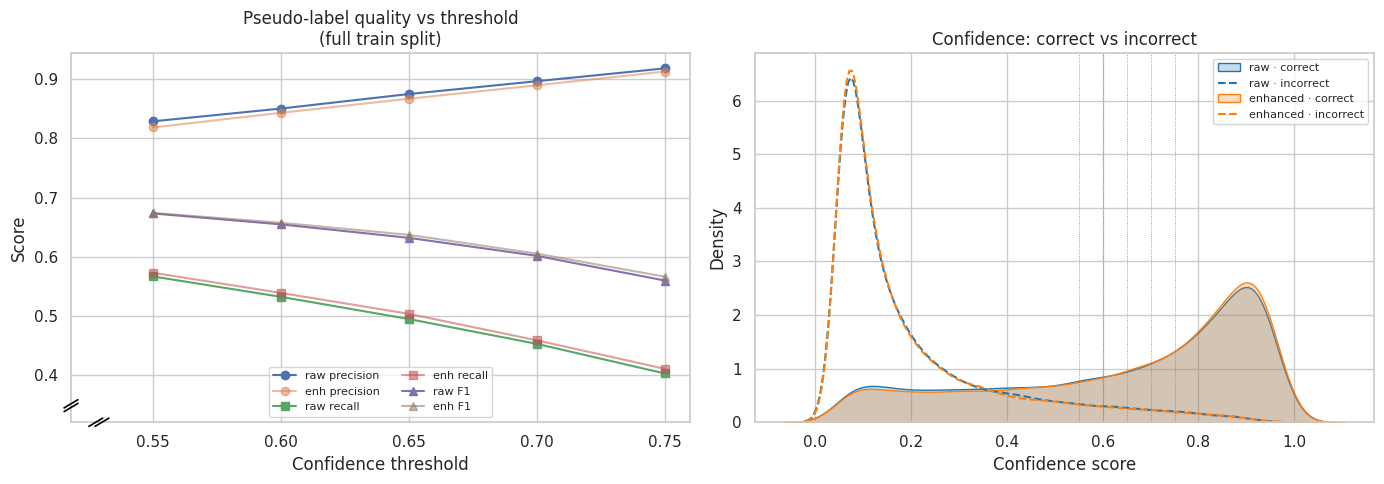

In [40]:
import seaborn as sns
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── left: quality curves ──
ax = axes[0]
for metric, style in [("precision", "-o"), ("recall", "-s"), ("F1", "-^")]:
    ax.plot(RAW_M.threshold, RAW_M[metric], style, label=f"raw {metric}")
    ax.plot(ENH_M.threshold, ENH_M[metric], style, alpha=0.55, label=f"enh {metric}")
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Score")
ax.set_title("Pseudo-label quality vs threshold\n(full train split)")
ax.legend(fontsize=8, ncol=2)

# pad left/bottom so ticks clear the break symbols (after all plotting)
x0, x1 = ax.get_xlim(); ax.set_xlim(x0 - 0.10 * (x1 - x0), x1)
y0, y1 = ax.get_ylim(); ax.set_ylim(y0 - 0.10 * (y1 - y0), y1)
mark_axis_break(ax)

# ── right: confidence separation (axes start at 0 -> no padding, no break marks) ──
ax = axes[1]
for cond, color in [("raw", "tab:blue"), ("enhanced", "tab:orange")]:
    sub = DFP[DFP.condition == cond]
    sns.kdeplot(data=sub[sub.tp], x="score", ax=ax, color=color, fill=True, alpha=0.25,
                common_norm=False, label=f"{cond} · correct")
    sns.kdeplot(data=sub[~sub.tp], x="score", ax=ax, color=color, ls="--",
                common_norm=False, label=f"{cond} · incorrect")
for t in CFG.thresholds:
    ax.axvline(t, ls=":", lw=0.6, color="grey")
ax.set_xlabel("Confidence score"); ax.set_title("Confidence: correct vs incorrect")
ax.legend(fontsize=8)
mark_axis_break(ax)

plt.tight_layout(); plt.show()


### 10.2 Per-class pseudo-label quality (selected condition)

Per-class precision / recall / F1 at the Phase 0 threshold on the selected condition, which identifies the
classes that will be starved of pseudo-labels. Phase 0 already flagged **Table** as collapsing under every
teacher — this cell confirms it at scale and drives the per-class thresholds in §13.


Per-class quality — enhanced @ threshold 0.6


,class,GT,boxes_kept,TP,precision,recall,F1
0,Bus,559,531,481,0.906,0.860,0.883
1,Bicycle,909,673,599,0.890,0.659,0.757
2,Car,2352,1674,1436,0.858,0.611,0.713
3,Dog,818,644,518,0.804,0.633,0.709
4,People,5975,4040,3514,0.870,0.588,0.702
5,Cup,1352,1014,800,0.789,0.592,0.676
6,Motorbike,890,492,461,0.937,0.518,0.667
7,Cat,719,490,399,0.814,0.555,0.660
8,Bottle,1322,956,735,0.769,0.556,0.645
9,Chair,1892,1090,893,0.819,0.472,0.599


Low-coverage classes (recall < 0.15): ['Table']


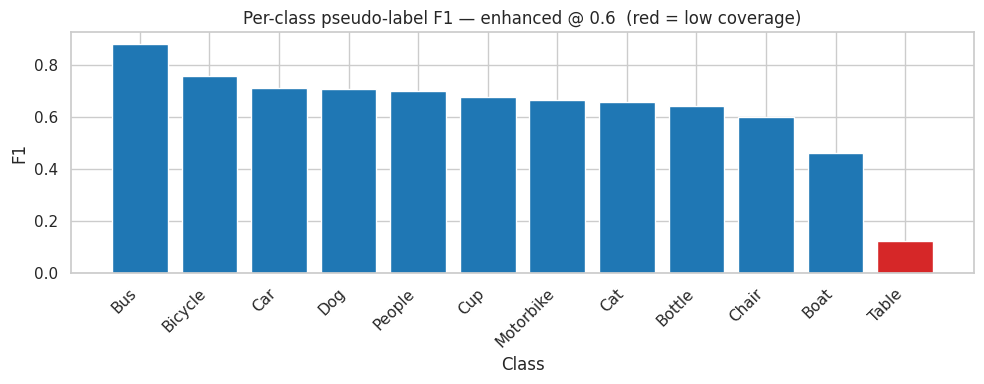

In [20]:
def per_class_metrics(condition, thr):
    gt_counts = {c: 0 for c in EXDARK_CLASSES}
    for s in TRAIN:
        for gc, _ in s["gt"]:
            gt_counts[gc] += 1
    agg = {c: {"tp": 0, "kept": 0} for c in EXDARK_CLASSES}
    for (key, cond), dets in PREDS_BY.items():
        if cond != condition:
            continue
        for d in dets:
            if d["score"] >= thr and d["cls"] in agg:
                agg[d["cls"]]["kept"] += 1
                agg[d["cls"]]["tp"] += int(d["tp"])
    rows = []
    for c in EXDARK_CLASSES:
        tp, kept, gt = agg[c]["tp"], agg[c]["kept"], gt_counts[c]
        prec = tp / kept if kept else 0.0
        rec = tp / gt if gt else 0.0
        f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) else 0.0
        rows.append({"class": c, "GT": gt, "boxes_kept": kept, "TP": tp,
                     "precision": round(prec, 3), "recall": round(rec, 3), "F1": round(f1, 3)})
    return pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)

PC = per_class_metrics(SELECTED_CONDITION, SELECTED_THRESHOLD)
print(f"Per-class quality — {SELECTED_CONDITION} @ threshold {SELECTED_THRESHOLD}")
display(PC)

WEAK_CLASSES = PC[PC.recall < 0.15]["class"].tolist()
print("Low-coverage classes (recall < 0.15):", WEAK_CLASSES)

# per-class F1 bar chart
fig, ax = plt.subplots(figsize=(10, 4))
_pc = PC.sort_values("F1", ascending=False)
ax.bar(_pc["class"], _pc["F1"], color=["tab:red" if c in WEAK_CLASSES else "tab:blue"
                                       for c in _pc["class"]])
ax.set_ylabel("F1"); ax.set_xlabel("Class")
ax.set_title(f"Per-class pseudo-label F1 — {SELECTED_CONDITION} @ {SELECTED_THRESHOLD}  "
             "(red = low coverage)")
plt.xticks(rotation=45, ha="right")
mark_axis_break(ax)
plt.tight_layout(); plt.show()


### 10.3 Per-class quality at both candidate thresholds

Section 10.2 evaluated the per-class breakdown at the Phase 0 threshold (0.60) only. Section 13
later finds that the full split favours 0.55, but the per-class view was never recomputed there.
This section closes that gap and tests whether the sweep's lower bound is itself the constraint.

**No re-inference is required.** Inference ran once at `infer_threshold = 0.05` and every
threshold is applied by filtering the cached predictions. The `tp` flags stay valid at any
threshold above 0.05 because `match_image` sorts detections by descending score before greedily
claiming ground-truth boxes, so removing lower-confidence rows cannot change the match assigned
to a surviving higher-confidence one.

The cells prefer the in-memory objects built above. If the notebook is opened on a fresh runtime
they fall back to reading the cached prediction table from Drive, so this section can also be run
on its own.

In [ ]:
# ── 10.3.1  Per-class metrics at an arbitrary threshold ────────────────────
import os, json
import pandas as pd
from IPython.display import display

try:                                    # normal in-order run
    per_class_metrics
    _MODE = "in-memory (per_class_metrics from 10.2)"
    def per_class_at(condition, thr):
        return per_class_metrics(condition, thr)
except NameError:                       # standalone run on a fresh runtime
    _MODE = "standalone (cached parquet from Drive)"
    RUN_TAG    = "yoloworld_v8"
    DRIVE_ROOT = "/content/drive/MyDrive/ExDark_dataset"
    if not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive; drive.mount("/content/drive")
    EXDARK_CLASSES = ["Bicycle","Boat","Bottle","Bus","Car","Cat",
                      "Chair","Cup","Dog","Motorbike","People","Table"]
    _DFP = pd.read_parquet(f"{DRIVE_ROOT}/phase1_predictions_{RUN_TAG}/train_predictions.parquet")
    _man = json.load(open(f"{DRIVE_ROOT}/phase1_outputs_{RUN_TAG}/split_manifest.json"))
    _GT = {c: 0 for c in EXDARK_CLASSES}
    for s in _man["samples"]:
        if s.get("split") == "train":
            for g in s["gt"]:
                if g[0] in _GT: _GT[g[0]] += 1
    def per_class_at(condition, thr):
        sub = _DFP[(_DFP.condition == condition) & (_DFP.score >= thr)]
        kept, tp = sub.groupby("cls").size(), sub.groupby("cls")["tp"].sum()
        rows = []
        for c in EXDARK_CLASSES:
            k, t, gt = int(kept.get(c, 0)), int(tp.get(c, 0)), _GT[c]
            p = t / k if k else 0.0
            r = t / gt if gt else 0.0
            f = (2*p*r/(p+r)) if (p+r) else 0.0
            rows.append({"class": c, "GT": gt, "boxes_kept": k, "TP": t,
                         "precision": round(p,3), "recall": round(r,3), "F1": round(f,3)})
        return pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)

print("mode:", _MODE)

# ── Validation against the Section 10.2 output ─────────────────────────────
REFERENCE_060 = {"Bus":(531,481), "Bicycle":(673,599), "Car":(1674,1436), "Dog":(644,518),
                 "People":(4040,3514), "Cup":(1014,800), "Motorbike":(492,461), "Cat":(490,399),
                 "Bottle":(956,735), "Chair":(1090,893), "Boat":(497,372), "Table":(99,81)}
_chk = per_class_at("enhanced", 0.60).set_index("class")
_bad = [f"  {c}: got kept={int(_chk.loc[c,'boxes_kept'])} TP={int(_chk.loc[c,'TP'])}, "
        f"expected kept={k} TP={t}"
        for c, (k, t) in REFERENCE_060.items()
        if (int(_chk.loc[c,"boxes_kept"]), int(_chk.loc[c,"TP"])) != (k, t)]
print("VALIDATION FAILED — do not use results below:\n" + "\n".join(_bad) if _bad
      else f"VALIDATION PASSED — reproduces 10.2 exactly "
           f"({int(_chk.boxes_kept.sum()):,} boxes, {int(_chk.TP.sum()):,} TP).")

In [ ]:
# ── 10.3.2  The two candidate thresholds, side by side ─────────────────────
PC_060 = per_class_at("enhanced", 0.60)
PC_055 = per_class_at("enhanced", 0.55)

print("=== Per-class quality — enhanced @ 0.60 ===");  display(PC_060)
print("=== Per-class quality — enhanced @ 0.55 ===");  display(PC_055)

CMP = (PC_060.set_index("class")[["GT","boxes_kept","TP","precision","recall","F1"]]
       .join(PC_055.set_index("class")[["boxes_kept","TP","precision","recall","F1"]],
             lsuffix="_060", rsuffix="_055"))
CMP["kept_gain%"]  = (100*(CMP.boxes_kept_055 - CMP.boxes_kept_060)/CMP.boxes_kept_060).round(1)
CMP["dPrecision"]  = (CMP.precision_055 - CMP.precision_060).round(3)
CMP["dRecall"]     = (CMP.recall_055 - CMP.recall_060).round(3)
CMP["dF1"]         = (CMP.F1_055 - CMP.F1_060).round(3)
CMP = CMP.sort_values("dF1", ascending=False)

print("=== 0.55 vs 0.60 (sorted by change in F1) ===");  display(CMP)
print("F1 improves at 0.55 for:", CMP.index[CMP.dF1 > 0].tolist())
print("F1 worsens  at 0.55 for:", CMP.index[CMP.dF1 < 0].tolist())
print("F1 unchanged           :", CMP.index[CMP.dF1 == 0].tolist())

In [ ]:
# ── 10.3.3  Is 0.55 a real optimum, or just the edge of the sweep? ─────────
# Section 12 selects a per-class threshold and returns 0.55 for all twelve classes,
# i.e. the lowest value offered. An optimiser that pins to the boundary for every
# class is evidence the search range, not the data, is the binding constraint.
# Predictions exist down to 0.05, so extending the sweep downward costs nothing.

SWEEP = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]

rows = []
for thr in SWEEP:
    t = per_class_at("enhanced", thr)
    tp, kept, gt = t.TP.sum(), t.boxes_kept.sum(), t.GT.sum()
    p, r = tp/kept, tp/gt
    rows.append({"threshold": thr, "boxes_kept": int(kept),
                 "precision": round(p,3), "recall": round(r,3),
                 "F1_pooled": round(2*p*r/(p+r),4),
                 "F1_macro": round(t.F1.mean(),4),
                 "min_class_F1": round(t.F1.min(),3),
                 "weakest_class": t.loc[t.F1.idxmin(), "class"]})
SWP = pd.DataFrame(rows)
print("=== Aggregate quality across an extended threshold sweep (enhanced) ===")
display(SWP)

best_p = SWP.loc[SWP.F1_pooled.idxmax(), "threshold"]
best_m = SWP.loc[SWP.F1_macro.idxmax(), "threshold"]
print(f"pooled F1 peaks at threshold {best_p}")
print(f"macro  F1 peaks at threshold {best_m}")
if min(best_p, best_m) <= min(SWEEP):
    print("\n>> Still rising at the lowest value tested. Extend SWEEP further down "
          "before treating any value as the optimum.")
elif min(best_p, best_m) < 0.55:
    print(f"\n>> Optimum lies BELOW 0.55. The 0.55 reported in Section 13 is a boundary "
          f"artefact of the original sweep (0.55-0.75), not a true maximum.")
else:
    print("\n>> 0.55 is a genuine interior optimum; the original sweep range was adequate.")

In [ ]:
# ── 10.3.4  Which classes would benefit from going below 0.55? ─────────────
# A low global threshold hurts classes whose low-confidence detections are unreliable,
# so the useful question is per class rather than overall.
# The sweep is computed once here and reused, rather than recomputed inside the loop.
TABLES = {thr: per_class_at("enhanced", thr).set_index("class") for thr in SWEEP}

best = []
for c in TABLES[0.55].index:
    curve = [(thr, TABLES[thr].loc[c]) for thr in SWEEP]
    thr_b, row_b = max(curve, key=lambda x: x[1].F1)
    row55 = TABLES[0.55].loc[c]
    best.append({"class": c, "best_thr": thr_b, "best_F1": round(row_b.F1, 3),
                 "F1_at_0.55": round(row55.F1, 3),
                 "gain_vs_0.55": round(row_b.F1 - row55.F1, 3),
                 "precision_at_best": round(row_b.precision, 3),
                 "recall_at_best": round(row_b.recall, 3),
                 "boxes_at_best": int(row_b.boxes_kept),
                 "boxes_at_0.55": int(row55.boxes_kept)})

BEST = pd.DataFrame(best).sort_values("gain_vs_0.55", ascending=False)
print("=== Best per-class threshold over the extended sweep ===")
display(BEST)

print("Classes preferring a threshold BELOW 0.55:",
      BEST.loc[BEST.best_thr < 0.55, "class"].tolist())
print("Classes preferring 0.55 or ABOVE          :",
      BEST.loc[BEST.best_thr >= 0.55, "class"].tolist())

_n_best = int(BEST.boxes_at_best.sum())
_n_flat = int(BEST["boxes_at_0.55"].sum())
print()
print("Boxes if each class used its own best threshold: {:,}".format(_n_best))
print("Boxes at a flat 0.55                          : {:,}".format(_n_flat))

try:
    OUT_DIR = CFG.outputs_dir
except NameError:
    OUT_DIR = "/content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8"
os.makedirs(OUT_DIR, exist_ok=True)
PC_055.to_csv(os.path.join(OUT_DIR, "per_class_quality_t055.csv"), index=False)
PC_060.to_csv(os.path.join(OUT_DIR, "per_class_quality_t060.csv"), index=False)
CMP.to_csv(os.path.join(OUT_DIR,  "per_class_quality_t055_vs_t060.csv"))
SWP.to_csv(os.path.join(OUT_DIR,  "threshold_sweep_extended.csv"), index=False)
BEST.to_csv(os.path.join(OUT_DIR, "per_class_best_threshold.csv"), index=False)
print("Saved 5 CSVs to", OUT_DIR)

## 11. Build RF-DETR-ready COCO datasets

The `rfdetr` package expects COCO folders — `train/`, `valid/`, `test/`, each with images plus an
`_annotations.coco.json`. Val/test **always** use human labels; only train annotations differ by
condition, and for Condition C only train changes with the threshold.

| Condition | Train labels | Train images | Val/Test labels | Val/Test images |
|-----------|--------------|--------------|-----------------|-----------------|
| **A** | human GT | raw | human GT | raw |
| **B** | human GT | enhanced | human GT | enhanced |
| **C** | **VLM pseudo-labels** | enhanced | human GT | enhanced |


In [21]:
def _xyxy_to_xywh_clipped(box, W, H):
    x1, y1, x2, y2 = box
    x1 = max(0.0, min(x1, W)); y1 = max(0.0, min(y1, H))
    x2 = max(0.0, min(x2, W)); y2 = max(0.0, min(y2, H))
    w = max(0.0, x2 - x1); h = max(0.0, y2 - y1)
    return [round(x1, 2), round(y1, 2), round(w, 2), round(h, 2)], w * h

def coco_file_name(s, cond):
    """Unique flat filename for a materialised folder (class-prefixed to avoid collisions)."""
    ext = os.path.splitext(s["path"])[1] if cond == "raw" else CFG.enh_ext
    return f"{s['primary_class']}__{os.path.splitext(s['filename'])[0]}{ext}"

def source_path(s, cond):
    return s["path"] if cond == "raw" else enhanced_path(CFG, s)

def make_coco(subset, boxes_of, cond):
    """boxes_of(sample) -> list of (class, [x1,y1,x2,y2]). Returns a COCO dict."""
    images, annotations, aid = [], [], 1
    for iid, s in enumerate(subset, start=1):
        W, H = s["width"], s["height"]
        images.append({"id": iid, "file_name": coco_file_name(s, cond), "width": W, "height": H})
        for cls, box in boxes_of(s):
            cat = CLASS_TO_CATID.get(cls)
            if cat is None:
                continue
            bbox, area = _xyxy_to_xywh_clipped(box, W, H)
            if bbox[2] <= 1 or bbox[3] <= 1:
                continue
            annotations.append({"id": aid, "image_id": iid, "category_id": cat,
                                "bbox": bbox, "area": round(area, 2), "iscrowd": 0})
            aid += 1
    return {"images": images, "annotations": annotations, "categories": COCO_CATEGORIES}

def _place(src, dst, mode):
    if os.path.exists(dst):
        return
    if mode == "symlink":
        try:
            os.symlink(os.path.abspath(src), dst); return
        except OSError:
            pass  # e.g. Drive FUSE — fall through to copy
    shutil.copy2(src, dst)

def materialize(name, spec, dest_root, image_mode):
    """spec: dict split -> (subset, boxes_of, cond), split in {train,val,test}.
    Writes <dest_root>/<name>/{train,valid,test}/ with images + _annotations.coco.json."""
    split_dir = {"train": "train", "val": "valid", "test": "test"}
    root = os.path.join(dest_root, name)
    summary = {}
    for split, (subset, boxes_of, cond) in spec.items():
        outdir = os.path.join(root, split_dir[split]); os.makedirs(outdir, exist_ok=True)
        coco = make_coco(subset, boxes_of, cond)
        for s, im in zip(subset, coco["images"]):
            _place(source_path(s, cond), os.path.join(outdir, im["file_name"]), image_mode)
        json.dump(coco, open(os.path.join(outdir, "_annotations.coco.json"), "w"))
        summary[split] = {"images": len(coco["images"]), "boxes": len(coco["annotations"]),
                          "condition": cond}
    print(f"[dataset] {name}: " +
          " | ".join(f"{k} {v['images']}img/{v['boxes']}box({v['condition']})"
                     for k, v in summary.items()))
    return root, summary

VAL   = [s for s in SAMPLES if s["split"] == "val"]
TEST  = [s for s in SAMPLES if s["split"] == "test"]
human = lambda s: s["gt"]
print(f"train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)}")


train 5886 | val 729 | test 748


### 11.1 Conditions A & B + the pseudo-label JSON bank

A and B are threshold-independent, so they're materialised once. For Condition C the **train** JSON is
written at every threshold (raw and enhanced, so the raw-VLM ablation stays available) into a bank on
Drive, each characterised by box count and coverage before any training commits.


In [22]:
DS_SUMMARIES = {}

# Condition A: raw + human, all splits
DS_SUMMARIES["A_raw_human"] = materialize(
    "A_raw_human",
    {"train": (TRAIN, human, "raw"), "val": (VAL, human, "raw"), "test": (TEST, human, "raw")},
    CFG.materialize_root, CFG.image_mode)[1]

# Condition B: enhanced + human, all splits
DS_SUMMARIES["B_enh_human"] = materialize(
    "B_enh_human",
    {"train": (TRAIN, human, "enhanced"), "val": (VAL, human, "enhanced"),
     "test": (TEST, human, "enhanced")},
    CFG.materialize_root, CFG.image_mode)[1]

# ── Pseudo-label JSON bank (train split only) for every threshold, both conditions ──
BANK_DIR = os.path.join(CFG.outputs_dir, "pseudo_label_bank"); os.makedirs(BANK_DIR, exist_ok=True)

def characterise(condition, thr):
    per_cls = {c: 0 for c in EXDARK_CLASSES}
    total = 0
    for s in TRAIN:
        for cls, _ in pseudo_boxes(s, condition, thr):
            per_cls[cls] += 1; total += 1
    imgs_with = sum(1 for s in TRAIN if pseudo_boxes(s, condition, thr))
    return {"condition": condition, "threshold": thr, "pseudo_boxes": total,
            "images_with_labels": imgs_with, "image_coverage": round(imgs_with / len(TRAIN), 3),
            "min_class_boxes": min(per_cls.values()), "per_class": per_cls}

char_rows = []
for cond in ("raw", "enhanced"):
    for t in CFG.thresholds:
        boxes_of = (lambda s, cc=cond, tt=t: pseudo_boxes(s, cc, tt))
        coco = make_coco(TRAIN, boxes_of, cond)
        path = os.path.join(BANK_DIR, f"train_{cond}_vlm_t{int(t*100)}.coco.json")
        json.dump(coco, open(path, "w"))
        ch = characterise(cond, t)
        ch["json"] = os.path.basename(path)
        char_rows.append(ch)

CHAR = pd.DataFrame([{k: v for k, v in r.items() if k != "per_class"} for r in char_rows])
print("=== Pseudo-label train-set characterisation (all thresholds) ===")
display(CHAR)
CHAR.to_csv(os.path.join(CFG.outputs_dir, "pseudo_label_characterisation.csv"), index=False)
print(f"\nPseudo-label JSON bank written to: {BANK_DIR}")


[dataset] A_raw_human: train 5886img/19105box(raw) | val 729img/2387box(raw) | test 748img/2218box(raw)
[dataset] B_enh_human: train 5886img/19105box(enhanced) | val 729img/2387box(enhanced) | test 748img/2218box(enhanced)
=== Pseudo-label train-set characterisation (all thresholds) ===


,condition,threshold,pseudo_boxes,images_with_labels,image_coverage,min_class_boxes,json
0,raw,0.55,13056,5181,0.880,123,train_raw_vlm_t55.coco.json
1,raw,0.60,11949,5059,0.859,82,train_raw_vlm_t60.coco.json
2,raw,0.65,10792,4924,0.837,48,train_raw_vlm_t65.coco.json
3,raw,0.70,9637,4724,0.803,28,train_raw_vlm_t70.coco.json
4,raw,0.75,8367,4459,0.758,10,train_raw_vlm_t75.coco.json
5,enhanced,0.55,13366,5134,0.872,131,train_enhanced_vlm_t55.coco.json
6,enhanced,0.60,12200,5012,0.852,99,train_enhanced_vlm_t60.coco.json
7,enhanced,0.65,11084,4861,0.826,70,train_enhanced_vlm_t65.coco.json
8,enhanced,0.70,9842,4664,0.792,36,train_enhanced_vlm_t70.coco.json
9,enhanced,0.75,8582,4410,0.749,15,train_enhanced_vlm_t75.coco.json



Pseudo-label JSON bank written to: /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/pseudo_label_bank


### 11.2 Materialise Condition C at the recommended threshold

The recommended threshold maximises **enhanced** pseudo-label F1 (Condition C trains on enhanced images).
Any other swept threshold can be built later with `materialize_condition_C(t)` — no re-inference needed.


In [23]:
_best_row = ENH_M.sort_values("F1", ascending=False).iloc[0]
REC_THRESHOLD = float(_best_row.threshold)
print(f"Recommended threshold (max enhanced F1): {REC_THRESHOLD}  "
      f"(P={_best_row.precision}, R={_best_row.recall}, F1={_best_row.F1})")
if abs(REC_THRESHOLD - SELECTED_THRESHOLD) > 1e-9:
    print(f"[note] Phase 0 selected {SELECTED_THRESHOLD} on 600 images; the full split favours "
          f"{REC_THRESHOLD}. The bank holds both, so either can be trained.")

def materialize_condition_C(thr, name=None):
    name = name or f"C_enh_vlm_t{int(thr*100)}"
    boxes_of = (lambda s, tt=thr: pseudo_boxes(s, "enhanced", tt))
    return materialize(
        name,
        {"train": (TRAIN, boxes_of, "enhanced"),
         "val":   (VAL,  human,    "enhanced"),
         "test":  (TEST, human,    "enhanced")},
        CFG.materialize_root, CFG.image_mode)

def materialize_condition_C_raw(thr, name=None):
    """Raw-VLM ablation builder."""
    name = name or f"Craw_raw_vlm_t{int(thr*100)}"
    boxes_of = (lambda s, tt=thr: pseudo_boxes(s, "raw", tt))
    return materialize(
        name,
        {"train": (TRAIN, boxes_of, "raw"),
         "val":   (VAL,  human,    "raw"),
         "test":  (TEST, human,    "raw")},
        CFG.materialize_root, CFG.image_mode)

_root, DS_SUMMARIES[f"C_enh_vlm_t{int(REC_THRESHOLD*100)}"] = materialize_condition_C(REC_THRESHOLD)
print("\nMaterialised datasets under:", CFG.materialize_root)
print(os.listdir(CFG.materialize_root))


Recommended threshold (max enhanced F1): 0.55  (P=0.8186, R=0.5727, F1=0.674)
[note] Phase 0 selected 0.6 on 600 images; the full split favours 0.55. The bank holds both, so either can be trained.
[dataset] C_enh_vlm_t55: train 5886img/13366box(enhanced) | val 729img/2387box(enhanced) | test 748img/2218box(enhanced)

Materialised datasets under: /content/phase1_datasets
['C_enh_vlm_t55', 'B_enh_human', 'A_raw_human']


### 11.3 Persist datasets to Drive

Local `/content` is wiped at session end, so each dataset is zipped and pushed to Drive (one large file
travels over FUSE far more reliably than thousands of small ones). Set `CFG.persist_to_drive = False` to
skip if Phase 2 runs in this same session.


In [24]:
def zip_and_push(name, root_dir, zip_dir):
    """Zip <root_dir>/<name> into a single archive under Drive zip_dir. Returns the Drive zip path."""
    os.makedirs(zip_dir, exist_ok=True)
    src = os.path.join(root_dir, name)
    local_zip = os.path.join("/content", name)            # zip on local disk first (fast)
    if os.path.isfile(local_zip + ".zip"):
        os.remove(local_zip + ".zip")
    shutil.make_archive(local_zip, "zip", src)
    drive_zip = os.path.join(zip_dir, name + ".zip")
    shutil.copy2(local_zip + ".zip", drive_zip)
    print(f"[persist] {name}.zip -> {drive_zip}  ({os.path.getsize(drive_zip)/1e6:.0f} MB)")
    return drive_zip

REC_NAME = f"C_enh_vlm_t{int(REC_THRESHOLD*100)}"
PERSISTED_ZIPS = {}
if CFG.persist_to_drive:
    for name in ["A_raw_human", "B_enh_human", REC_NAME]:
        if os.path.isdir(os.path.join(CFG.materialize_root, name)):
            PERSISTED_ZIPS[name] = zip_and_push(name, CFG.materialize_root, CFG.dataset_zip_dir)
else:
    print("[persist] skipped (CFG.persist_to_drive=False). Datasets exist only under",
          CFG.materialize_root, "for this session.")


[persist] A_raw_human.zip -> /content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_yoloworld_v8/A_raw_human.zip  (1489 MB)
[persist] B_enh_human.zip -> /content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_yoloworld_v8/B_enh_human.zip  (6631 MB)
[persist] C_enh_vlm_t55.zip -> /content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_yoloworld_v8/C_enh_vlm_t55.zip  (6631 MB)


## 12. Per-class thresholds — recover coverage for weak classes

Keeps a strict cut on strong classes but relaxes it for the low-coverage classes found in §10.2 (Phase 0
flagged **Table** in particular), so they aren't starved of pseudo-labels. Produces one extra train JSON
in the bank.


In [25]:
RELAXED = 0.55  # relaxed threshold for weak classes
PER_CLASS_THR = {c: (RELAXED if c in WEAK_CLASSES else REC_THRESHOLD) for c in EXDARK_CLASSES}
print("Per-class thresholds:", PER_CLASS_THR)

def pseudo_boxes_perclass(sample, condition):
    return [(d["cls"], d["box"]) for d in PREDS_BY.get((sample["key"], condition), [])
            if d["score"] >= PER_CLASS_THR.get(d["cls"], REC_THRESHOLD)]

_pc_boxes = lambda s: pseudo_boxes_perclass(s, "enhanced")
_pc_coco = make_coco(TRAIN, _pc_boxes, "enhanced")
_pc_path = os.path.join(BANK_DIR, "train_enhanced_vlm_perclass.coco.json")
json.dump(_pc_coco, open(_pc_path, "w"))

_pc_per_cls = {c: 0 for c in EXDARK_CLASSES}
for s in TRAIN:
    for cls, _ in _pc_boxes(s):
        _pc_per_cls[cls] += 1

_flat = pd.DataFrame({"pseudo_boxes": pd.Series(_pc_per_cls)})
_flat["threshold_used"] = [PER_CLASS_THR[c] for c in _flat.index]
print(f"\nPer-class pseudo-label set: {len(_pc_coco['annotations'])} boxes, "
      f"min class = {min(_pc_per_cls.values())}")
display(_flat)

# any class still empty cannot be learned from pseudo-labels at all — flag it explicitly
_empty = [c for c, n in _pc_per_cls.items() if n == 0]
if _empty:
    print(f"[WARN] Classes with ZERO pseudo-labels even at the relaxed cut: {_empty}. "
          "Condition C cannot learn these — expect them at ~0 AP in Phase 2, and consider a "
          "human-label fallback for them.")

print(f"Saved: {_pc_path}")


Per-class thresholds: {'Bicycle': 0.55, 'Boat': 0.55, 'Bottle': 0.55, 'Bus': 0.55, 'Car': 0.55, 'Cat': 0.55, 'Chair': 0.55, 'Cup': 0.55, 'Dog': 0.55, 'Motorbike': 0.55, 'People': 0.55, 'Table': 0.55}

Per-class pseudo-label set: 13366 boxes, min class = 131


,pseudo_boxes,threshold_used
Bicycle,725,0.55
Boat,565,0.55
Bottle,1063,0.55
Bus,549,0.55
Car,1829,0.55
Cat,516,0.55
Chair,1236,0.55
Cup,1117,0.55
Dog,683,0.55
Motorbike,536,0.55


Saved: /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/pseudo_label_bank/train_enhanced_vlm_perclass.coco.json


## 13. Comparative analysis & verdict

Pulls the phase together: the large-sample raw-vs-enhanced verdict, and the precision/coverage trade-off
per threshold that Phase 2 picks an operating point from.


VERDICT (raw vs enhanced, full split)
--------------------------------------------
ENHANCEMENT HELPS: enhanced pseudo-labels beat raw at most thresholds (5/5), mean dF1 = +0.0038. This supports the Phase 0 selection of the enhanced condition.



,threshold,precision_raw,recall_raw,F1_raw,precision_enh,recall_enh,F1_enh,dF1(enh-raw)
0,0.55,0.8290,0.5665,0.6731,0.8186,0.5727,0.6740,0.0009
1,0.60,0.8506,0.5320,0.6546,0.8434,0.5386,0.6573,0.0027
2,0.65,0.8752,0.4944,0.6318,0.8673,0.5032,0.6369,0.0051
3,0.70,0.8969,0.4524,0.6014,0.8899,0.4584,0.6051,0.0037
4,0.75,0.9186,0.4023,0.5596,0.9132,0.4102,0.5661,0.0065


Precision / coverage trade-off — enhanced condition


,threshold,precision,recall,F1,boxes_kept,image_coverage,min_class_boxes
0,0.55,0.8186,0.5727,0.6740,13366,0.872,131
1,0.60,0.8434,0.5386,0.6573,12200,0.852,99
2,0.65,0.8673,0.5032,0.6369,11084,0.826,70
3,0.70,0.8899,0.4584,0.6051,9842,0.792,36
4,0.75,0.9132,0.4102,0.5661,8582,0.749,15


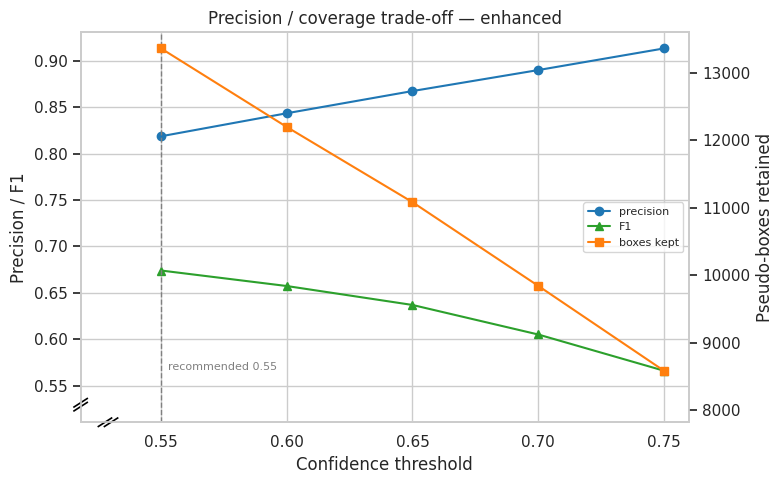

In [39]:
# ── (1) Raw vs Enhanced verdict, confirming or overturning Phase 0 ──
wins_enh = int((CMP["dF1(enh-raw)"] > 0).sum())
wins_raw = int((CMP["dF1(enh-raw)"] < 0).sum())
mean_dF1 = float(CMP["dF1(enh-raw)"].mean())
if wins_enh > wins_raw and mean_dF1 > 0:
    verdict = ("ENHANCEMENT HELPS: enhanced pseudo-labels beat raw at most thresholds "
               f"({wins_enh}/{len(CMP)}), mean dF1 = {mean_dF1:+.4f}. This supports the Phase 0 "
               "selection of the enhanced condition.")
elif wins_raw > wins_enh and mean_dF1 < 0:
    verdict = ("RAW WINS: enhancement does NOT improve pseudo-label quality "
               f"({wins_raw}/{len(CMP)} thresholds favour raw), mean dF1 = {mean_dF1:+.4f}. "
               "Condition C's enhanced images are then justified by training-time robustness, "
               "not cleaner labels.")
else:
    verdict = (f"MIXED/NEUTRAL: raw and enhanced are within noise (mean dF1 = {mean_dF1:+.4f}). "
               "Enhancement neither meaningfully helps nor hurts pseudo-label quality — matching "
               "the near-tie Phase 0 saw on 600 images.")
print("VERDICT (raw vs enhanced, full split)\n" + "-" * 44 + f"\n{verdict}\n")
display(CMP)

# ── (2) Precision / coverage trade-off per threshold ──
win_cond = "enhanced" if (wins_enh > wins_raw and mean_dF1 > 0) else "raw"
TRADEOFF = (ENH_M if win_cond == "enhanced" else RAW_M).copy()
TRADEOFF["image_coverage"] = [
    round(sum(1 for s in TRAIN if pseudo_boxes(s, win_cond, t)) / len(TRAIN), 3)
    for t in TRADEOFF.threshold]
TRADEOFF["min_class_boxes"] = [
    min(characterise(win_cond, t)["per_class"].values()) for t in TRADEOFF.threshold]
print(f"Precision / coverage trade-off — {win_cond} condition")
display(TRADEOFF[["threshold", "precision", "recall", "F1", "boxes_kept",
                 "image_coverage", "min_class_boxes"]])

# ── (3) Trade-off plot ──
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(TRADEOFF.threshold, TRADEOFF.precision, "-o", color="tab:blue", label="precision")
ax1.plot(TRADEOFF.threshold, TRADEOFF.F1, "-^", color="tab:green", label="F1")
ax1.set_xlabel("Confidence threshold"); ax1.set_ylabel("Precision / F1")
ax1.axvline(REC_THRESHOLD, ls="--", lw=1, color="grey")
ax1.annotate(f"recommended {REC_THRESHOLD}", (REC_THRESHOLD, ax1.get_ylim()[0]),
             textcoords="offset points", xytext=(5, 12), fontsize=8, color="grey")

ax2 = ax1.twinx()
ax2.plot(TRADEOFF.threshold, TRADEOFF.boxes_kept, "-s", color="tab:orange", label="boxes kept")
ax2.set_ylabel("Pseudo-boxes retained"); ax2.grid(False)

# ── pad left/bottom so ticks clear the break symbols (after all plotting) ──
x0, x1 = ax1.get_xlim(); ax1.set_xlim(x0 - 0.10 * (x1 - x0), x1)
y0, y1 = ax1.get_ylim(); ax1.set_ylim(y0 - 0.10 * (y1 - y0), y1)
y0, y1 = ax2.get_ylim(); ax2.set_ylim(y0 - 0.10 * (y1 - y0), y1)

lines = ax1.get_lines()[:2] + ax2.get_lines()[:1]
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)
ax1.set_title(f"Precision / coverage trade-off — {win_cond}")
mark_axis_break(ax1)
plt.tight_layout(); plt.show()


## 14. Persist Phase 1 outputs & the Phase 2 handoff

Writes the metric CSVs, `phase1_summary.json`, and `phase1_manifest.json` — the file Phase 2 reads to
locate the datasets, enhanced pool, pseudo-label bank and recommended threshold.


In [27]:
PHASE1_SUMMARY = {
    "teacher": CFG.teacher_name,
    "teacher_weights": CFG.yoloworld_id,
    "phase0_decision": PHASE0,
    "train_val_test": {k: int(v) for k, v in Counter(s["split"] for s in SAMPLES).items()},
    "train_gt_boxes": TRAIN_GT_TOTAL,
    "thresholds": list(CFG.thresholds),
    "raw_vs_enhanced_verdict": verdict,
    "winning_condition": win_cond,
    "recommended_threshold": REC_THRESHOLD,
    "recommended_metrics": ENH_M.sort_values("F1", ascending=False).iloc[0].to_dict(),
    "pseudo_label_bank": BANK_DIR,
    "materialized_root": CFG.materialize_root,
    "datasets": list(DS_SUMMARIES.keys()),
    "weak_classes": WEAK_CLASSES,
    "per_class_thresholds": PER_CLASS_THR,
}

RAW_M.to_csv(os.path.join(CFG.outputs_dir, "metrics_raw.csv"), index=False)
ENH_M.to_csv(os.path.join(CFG.outputs_dir, "metrics_enhanced.csv"), index=False)
CMP.to_csv(os.path.join(CFG.outputs_dir, "metrics_raw_vs_enhanced.csv"), index=False)
TRADEOFF.to_csv(os.path.join(CFG.outputs_dir, "precision_coverage_tradeoff.csv"), index=False)
PC.to_csv(os.path.join(CFG.outputs_dir, "per_class_quality.csv"), index=False)
json.dump(PHASE1_SUMMARY, open(os.path.join(CFG.outputs_dir, "phase1_summary.json"), "w"),
          indent=2, default=str)

# ── Phase 1 -> Phase 2 handoff manifest ──
PHASE1_MANIFEST = {
    "run_tag": RUN_TAG,
    "classes": EXDARK_CLASSES,
    "coco_categories": COCO_CATEGORIES,
    "split": {"ratios": list(CFG.split_ratios), "seed": CFG.random_seed,
              "sizes": {k: int(v) for k, v in Counter(s["split"] for s in SAMPLES).items()}},
    "teacher": CFG.teacher_name,
    "teacher_weights": CFG.yoloworld_id,
    "recommended_threshold": REC_THRESHOLD,
    "recommended_condition_C_dataset": REC_NAME,
    "thresholds": list(CFG.thresholds),
    "enhanced_pool_dir": CFG.enhanced_pool_dir,
    "enh_ext": CFG.enh_ext,
    "pseudo_label_bank": BANK_DIR,
    "dataset_zip_dir": CFG.dataset_zip_dir,
    "persisted_zips": PERSISTED_ZIPS,
    "split_manifest": SPLIT_CACHE,
    "images_dir": CFG.images_dir,
    "annot_dir": CFG.annot_dir,
}
MANIFEST_PATH = os.path.join(CFG.outputs_dir, "phase1_manifest.json")
json.dump(PHASE1_MANIFEST, open(MANIFEST_PATH, "w"), indent=2, default=str)

print("Phase 1 outputs written to:", CFG.outputs_dir)
for f in sorted(os.listdir(CFG.outputs_dir)):
    print("  -", f)
print("\n[handoff] wrote", MANIFEST_PATH)
print("\nPhase 1 summary:")
print(json.dumps({k: v for k, v in PHASE1_SUMMARY.items()
                  if k not in ("per_class_thresholds", "recommended_metrics")},
                 indent=2, default=str))


Phase 1 outputs written to: /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8
  - metrics_enhanced.csv
  - metrics_raw.csv
  - metrics_raw_vs_enhanced.csv
  - per_class_quality.csv
  - phase1_manifest.json
  - phase1_summary.json
  - precision_coverage_tradeoff.csv
  - pseudo_label_bank
  - pseudo_label_characterisation.csv
  - split_manifest.json

[handoff] wrote /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/phase1_manifest.json

Phase 1 summary:
{
  "teacher": "YOLO-World",
  "teacher_weights": "yolov8x-worldv2.pt",
  "phase0_decision": {
    "selected_teacher": "YOLO-World",
    "selected_condition": "enhanced",
    "selected_threshold": 0.6,
    "precision": 0.8486,
    "kept_boxes": 1255,
    "min_class_survival": 13,
    "min_per_class_requirement": 10,
    "sample_size": 600
  },
  "train_val_test": {
    "train": 5886,
    "val": 729,
    "test": 748
  },
  "train_gt_boxes": 19105,
  "thresholds": [
    0.55,
    0.6,
    0.65,
    0.7,
    0

## 16. What Phase 1 hands to Phase 2

1. **Three COCO datasets** — `A_raw_human`, `B_enh_human`, `C_enh_vlm_t{rec}` — zipped to
   `phase1_datasets_zip_yoloworld_v8/`, each with `train/ valid/ test/` and `_annotations.coco.json`.
2. **A pseudo-label bank** holding train annotations at every threshold (raw + enhanced) plus the
   per-class-threshold variant, so Condition C can be rebuilt at any operating point without re-inference.
3. **`phase1_manifest.json` + `phase1_summary.json`** — the raw-vs-enhanced verdict at scale, the
   recommended threshold, and the metric CSVs backing the report tables.

Phase 2 trains three structurally identical RF-DETR-Base instances on A, B and C with the same
hyper-parameters, validates on the human-labelled split, and compares mAP@0.5 / mAP@[.5:.95] to test the
`C > B > A` hypothesis. Watch the classes flagged in §12 — any class with zero pseudo-labels will sit near
0 AP under Condition C by construction, and should be reported as a coverage limitation rather than a
model failure.
